# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Nugraheni Dwi Ayu Putri
- **Email:** ds001b6x1400@student.devacademy.id
- **ID Dicoding:** DS001B6X1400

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca terhadap rata-rata jumlah penyewaan sepeda harian selama tahun 2011 dan 2012, dan di kondisi cuaca mana penyewaan paling rendah?
- **Pertanyaan 2:** Pada jam berapa saja jumlah penyewaan sepeda mencapai puncak pada hari kerja dibandingkan hari libur selama tahun 2011-2012, sehingga kapan waktu terbaik untuk menambah ketersediaan sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Memuat seluruh dataset yang diperlukan untuk analisis. Data dimuat dari file day.csv dan hour.csv ke dalam DataFrame.

#### Load DataFrame

In [2]:
hour_df = pd.read_csv("hour.csv")
day_df = pd.read_csv("day.csv")

In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
print("day_df :", day_df.shape)
print("hour_df :", hour_df.shape)

day_df : (731, 16)
hour_df : (17379, 17)


**Insight:**
- `day_df` berisi 731 baris dan 16 kolom: data penyewaan harian dari 1 Januari 2011 sampai 31 Desember 2012.
- `hour_df` berisi 17.379 baris dan 17 kolom: data yang sama, tetapi dirinci per jam. Perbedaannya hanya kolom `hr` (jam 0-23).
- Karena itu, `day_df` dipakai untuk menganalisis pengaruh cuaca (Pertanyaan 1), dan `hour_df` untuk pola jam puncak (Pertanyaan 2).
- Kolom `cnt` adalah total penyewaan (`casual` + `registered`) dan menjadi kolom utama yang dianalisis.
- Beberapa kolom (`season`, `weathersit`, `yr`) masih berupa kode angka dan `dteday` masih berupa teks. Ini akan ditangani di tahap Assessing dan Cleaning.

### Assessing Data

#### Menilai Data day_df

In [6]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [7]:
print("Missing value:\n", day_df.isna().sum())

Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [8]:
print("Jumlah duplikasi:", day_df.duplicated().sum())

Jumlah duplikasi: 0


In [9]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Menilai Data hour_df

In [10]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [11]:
print("Missing value:\n", hour_df.isna().sum())

Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [12]:
print("Jumlah duplikasi:", hour_df.duplicated().sum())

Jumlah duplikasi: 0


In [13]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Mengubah tipe data `dteday` dari `object` menjadi `datetime`.
- Mengganti kode angka pada `season`, `yr`, dan `weathersit` menjadi label yang mudah dibaca.
- Membuat kolom `day_type` (Hari Kerja / Libur) dari kolom `workingday`.
- Mengonversi `temp` ke satuan Celsius agar mudah ditafsirkan.

**Insight:**
- Tidak ditemukan missing value maupun data duplikat pada `day_df` dan `hour_df`, sehingga kualitas data baik.
- `dteday` bertipe teks (`object`), padahal berisi tanggal.
- `season`, `yr`, dan `weathersit` masih berupa kode angka sehingga kurang informatif.
- `temp`, `atemp`, `hum`, dan `windspeed` masih bernilai ternormalisasi (0-1).

### Cleaning Data

#### Memperbaiki Tipe Data dan Label

In [14]:
season_map = {1: "Semi", 2: "Panas", 3: "Gugur", 4: "Dingin"}
weather_map = {1: "Cerah", 2: "Berkabut", 3: "Hujan/Salju Ringan", 4: "Cuaca Ekstrem"}
year_map = {0: 2011, 1: 2012}

for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])
    df["season"] = df["season"].map(season_map)
    df["weathersit"] = df["weathersit"].map(weather_map)
    df["yr"] = df["yr"].map(year_map)
    df["day_type"] = df["workingday"].map({1: "Hari Kerja", 0: "Libur"})
    df["temp_celsius"] = df["temp"] * 47 - 8

In [15]:
day_df.info()
day_df[["dteday", "season", "yr", "weathersit", "day_type", "temp_celsius"]].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   instant       731 non-null    int64         
 1   dteday        731 non-null    datetime64[ns]
 2   season        731 non-null    object        
 3   yr            731 non-null    int64         
 4   mnth          731 non-null    int64         
 5   holiday       731 non-null    int64         
 6   weekday       731 non-null    int64         
 7   workingday    731 non-null    int64         
 8   weathersit    731 non-null    object        
 9   temp          731 non-null    float64       
 10  atemp         731 non-null    float64       
 11  hum           731 non-null    float64       
 12  windspeed     731 non-null    float64       
 13  casual        731 non-null    int64         
 14  registered    731 non-null    int64         
 15  cnt           731 non-null    int64     

,dteday,season,yr,weathersit,day_type,temp_celsius
0,2011-01-01,Semi,2011,Berkabut,Libur,8.175849
1,2011-01-02,Semi,2011,Berkabut,Libur,9.083466
2,2011-01-03,Semi,2011,Cerah,Hari Kerja,1.229108
3,2011-01-04,Semi,2011,Cerah,Hari Kerja,1.400000
4,2011-01-05,Semi,2011,Cerah,Hari Kerja,2.666979


In [16]:
hour_df.info()
hour_df[["dteday", "hr", "season", "yr", "weathersit", "day_type", "temp_celsius"]].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   instant       17379 non-null  int64         
 1   dteday        17379 non-null  datetime64[ns]
 2   season        17379 non-null  object        
 3   yr            17379 non-null  int64         
 4   mnth          17379 non-null  int64         
 5   hr            17379 non-null  int64         
 6   holiday       17379 non-null  int64         
 7   weekday       17379 non-null  int64         
 8   workingday    17379 non-null  int64         
 9   weathersit    17379 non-null  object        
 10  temp          17379 non-null  float64       
 11  atemp         17379 non-null  float64       
 12  hum           17379 non-null  float64       
 13  windspeed     17379 non-null  float64       
 14  casual        17379 non-null  int64         
 15  registered    17379 non-null  int64 

,dteday,hr,season,yr,weathersit,day_type,temp_celsius
0,2011-01-01,0,Semi,2011,Cerah,Libur,3.28
1,2011-01-01,1,Semi,2011,Cerah,Libur,2.34
2,2011-01-01,2,Semi,2011,Cerah,Libur,2.34
3,2011-01-01,3,Semi,2011,Cerah,Libur,3.28
4,2011-01-01,4,Semi,2011,Cerah,Libur,3.28


**Insight:**
- `dteday` pada `day_df` dan `hour_df` sudah bertipe `datetime64`.
- Kolom `season`, `yr`, dan `weathersit` kini berupa label yang mudah dibaca.
- Kolom `day_type` ditambahkan untuk membandingkan hari kerja dan hari libur (`workingday = 0` mencakup akhir pekan dan hari libur nasional).
- Kolom `temp_celsius` dibuat agar suhu dapat ditafsirkan dalam satuan Celsius.
- Pembersihan dilakukan pada kedua DataFrame dengan aturan yang sama, sehingga hasil analisis keduanya konsisten.

## Exploratory Data Analysis (EDA)

### Eksplorasi Pengaruh Cuaca

In [17]:
weather_order = ["Cerah", "Berkabut", "Hujan/Salju Ringan"]
weather_summary = (day_df.groupby("weathersit")["cnt"]
                   .agg(["count", "mean", "min", "max"])
                   .reindex(weather_order).round(0))
weather_summary

,count,mean,min,max
weathersit,,,,
Cerah,463,4877.0,431,8714
Berkabut,247,4036.0,605,8362
Hujan/Salju Ringan,21,1803.0,22,4639


In [18]:
day_df.pivot_table(index="weathersit", columns="yr", values="cnt", aggfunc="mean").reindex(weather_order).round(0)

yr,2011,2012
weathersit,,
Cerah,3695.0,6004.0
Berkabut,3088.0,4991.0
Hujan/Salju Ringan,1674.0,2126.0


**Insight:**
- Rata-rata penyewaan tertinggi terjadi saat cuaca cerah (4.877 sepeda/hari), sedangkan terendah saat hujan/salju ringan (1.803 sepeda/hari), atau sekitar 63% lebih rendah dari cuaca cerah.
- Cuaca berkabut berada di tengah (4.036 sepeda/hari), sekitar 17% lebih rendah dari cuaca cerah.
- Pola yang sama muncul pada tahun 2011 maupun 2012, dan penyewaan tahun 2012 lebih tinggi dari 2011.
- Catatan: kategori hujan/salju ringan hanya mencakup 21 hari, jauh lebih sedikit dari cuaca cerah (463 hari), jadi angkanya perlu ditafsirkan dengan hati-hati.

#### Eksplorasi Pola Jam

In [19]:
hour_pivot = (hour_df.groupby(["hr", "day_type"])["cnt"].mean()
              .unstack().round(0))
hour_pivot

day_type,Hari Kerja,Libur
hr,,
0,37.0,91.0
1,17.0,70.0
2,9.0,53.0
3,5.0,26.0
4,5.0,8.0
5,25.0,9.0
6,102.0,19.0
7,291.0,43.0
8,477.0,106.0


In [20]:
print("3 jam tertinggi:")
for tipe in hour_pivot.columns:
    print(tipe, "->", hour_pivot[tipe].nlargest(3).to_dict())

3 jam tertinggi:
Hari Kerja -> {17: 525.0, 18: 492.0, 8: 477.0}
Libur -> {13: 373.0, 12: 366.0, 14: 365.0}


**Insight:**
- Pada hari kerja, penyewaan memuncak pada jam 17.00 (525), 18.00 (492), dan 08.00 (477), sesuai pola berangkat dan pulang kerja.
- Pada hari libur, puncak penyewaan terjadi sekitar jam 12.00 sampai 14.00 (365-373) dan polanya lebih landai.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca terhadap rata-rata penyewaan harian?

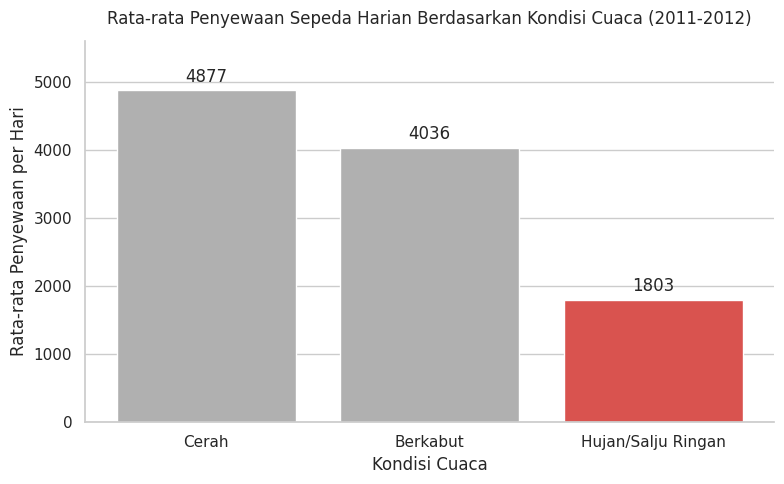

In [28]:
avg_weather = day_df.groupby("weathersit")["cnt"].mean().reindex(weather_order)

colors = ["#B0B0B0"] * len(avg_weather)
colors[avg_weather.values.argmin()] = "#D9534F"

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg_weather.index, avg_weather.values, color=colors)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylim(0, avg_weather.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_title("Rata-rata Penyewaan Sepeda Harian Berdasarkan Kondisi Cuaca (2011-2012)", pad=12)
ax.set_xlabel("Kondisi Cuaca")
ax.set_ylabel("Rata-rata Penyewaan per Hari")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Insight:**
- Penyewaan turun seiring memburuknya cuaca: 4.877 (cerah), 4.036 (berkabut), dan 1.803 (hujan/salju ringan) sepeda per hari.
- Hujan/salju ringan menjadi kondisi dengan penyewaan terendah, sekitar 63% di bawah cuaca cerah.
- Catatan: kategori hujan/salju ringan hanya mencakup 21 hari (cerah 463 hari, berkabut 247 hari), jadi angkanya perlu ditafsirkan dengan hati-hati.

### Pertanyaan 2: Pada jam berapa penyewaan memuncak pada hari kerja dibandingkan hari libur?

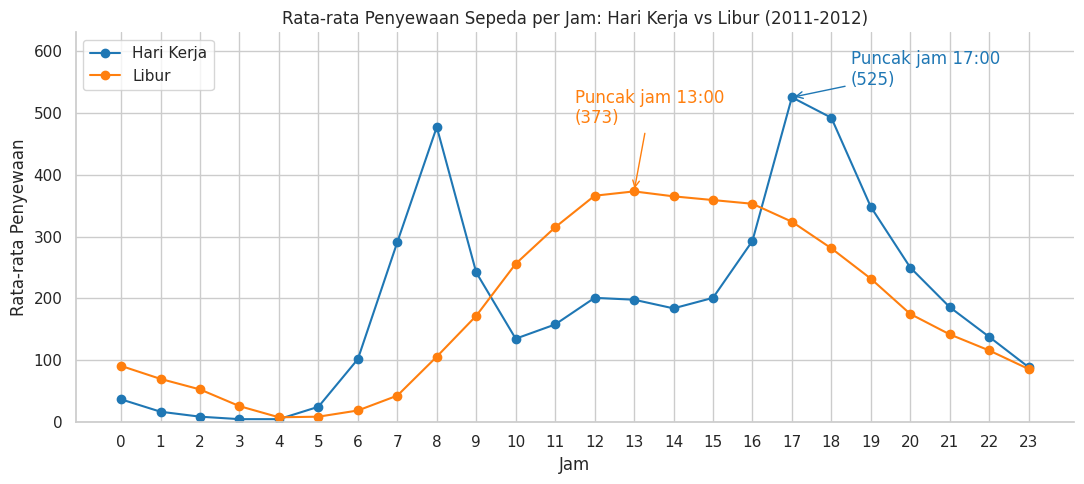

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hour_pivot.index, hour_pivot["Hari Kerja"], marker="o", color="#1F77B4", label="Hari Kerja")
ax.plot(hour_pivot.index, hour_pivot["Libur"], marker="o", color="#FF7F0E", label="Libur")

peak_kerja = hour_pivot["Hari Kerja"].idxmax()
peak_libur = hour_pivot["Libur"].idxmax()
ax.annotate(f"Puncak jam {peak_kerja}:00\n({hour_pivot['Hari Kerja'].max():.0f})",
            xy=(peak_kerja, hour_pivot["Hari Kerja"].max()),
            xytext=(peak_kerja + 1.5, hour_pivot["Hari Kerja"].max() + 20),
            arrowprops=dict(arrowstyle="->", color="#1F77B4"), color="#1F77B4")
ax.annotate(f"Puncak jam {peak_libur}:00\n({hour_pivot['Libur'].max():.0f})",
            xy=(peak_libur, hour_pivot["Libur"].max()),
            xytext=(peak_libur - 1.5, hour_pivot["Libur"].max() + 110),
            arrowprops=dict(arrowstyle="->", color="#FF7F0E"), color="#FF7F0E")

ax.set_xticks(range(0, 24))
ax.set_ylim(0, hour_pivot.max().max() * 1.2)
ax.set_title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Libur (2011-2012)")
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata Penyewaan")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja ada dua puncak yang tajam, yaitu sekitar jam 08.00 (477) dan jam 17.00-18.00 (525 dan 492), sesuai jam berangkat dan pulang kerja.
- Pada hari libur penyewaan memuncak di siang hari (jam 12.00-14.00, sekitar 365-373) dengan pola yang lebih landai.
- Puncak sore hari kerja sekitar 41% lebih tinggi dari puncak hari libur.

## Analisis Lanjutan: Binning (Manual Grouping)

In [23]:
hour_df["time_segment"] = pd.cut(
    hour_df["hr"], bins=[-1, 5, 10, 15, 19, 23],
    labels=["Dini Hari (00-05)", "Pagi (06-10)", "Siang (11-15)", "Sore (16-19)", "Malam (20-23)"])

segment_avg = hour_df.groupby("time_segment", observed=True)["cnt"].mean().round(0)
segment_avg

,cnt
time_segment,
Dini Hari (00-05),25.0
Pagi (06-10),208.0
Siang (11-15),241.0
Sore (16-19),378.0
Malam (20-23),154.0


In [24]:
day_df["temp_category"] = pd.cut(
    day_df["temp_celsius"], bins=[-10, 10, 20, 30, 40],
    labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])

temp_summary = day_df.groupby("temp_category", observed=True)["cnt"].agg(["count", "mean"]).round(0)
temp_summary

,count,mean
temp_category,,
Dingin (<10°C),240,2893.0
Sejuk (10-20°C),230,4870.0
Hangat (20-30°C),249,5706.0
Panas (>30°C),12,4804.0


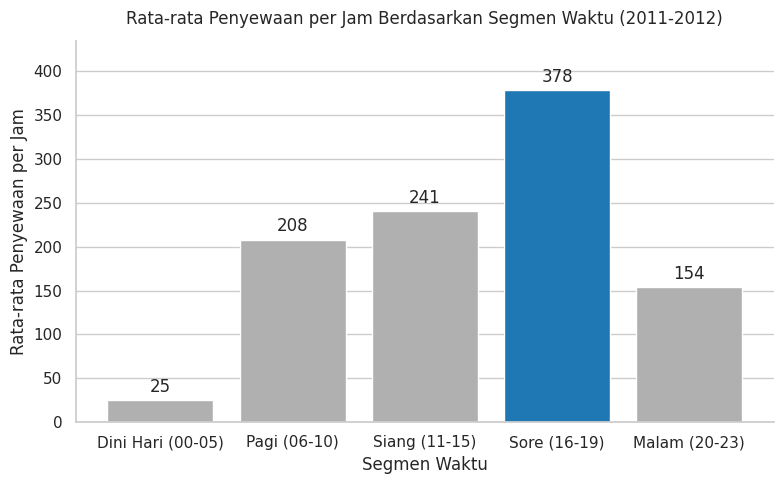

In [25]:
colors = ["#B0B0B0"] * len(segment_avg)
colors[segment_avg.values.argmax()] = "#1F77B4"

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(segment_avg.index, segment_avg.values, color=colors)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylim(0, segment_avg.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_title("Rata-rata Penyewaan per Jam Berdasarkan Segmen Waktu (2011-2012)", pad=12)
ax.set_xlabel("Segmen Waktu")
ax.set_ylabel("Rata-rata Penyewaan per Jam")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

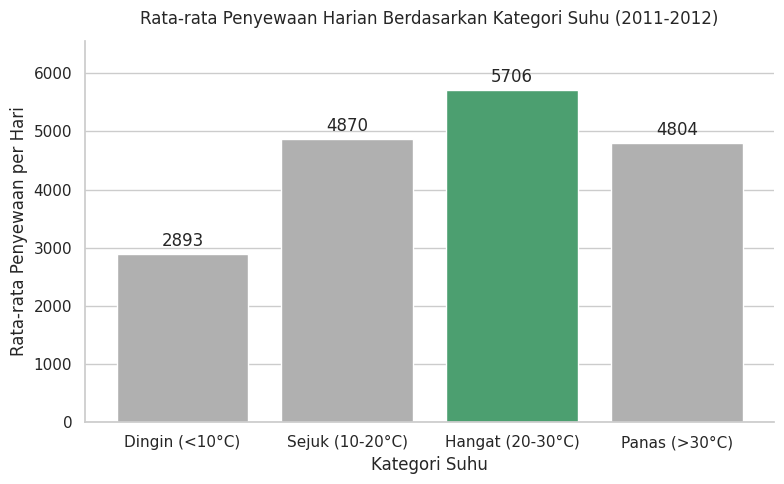

In [26]:
temp_avg = temp_summary["mean"]
colors = ["#B0B0B0"] * len(temp_avg)
colors[temp_avg.values.argmax()] = "#4C9F70"

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(temp_avg.index.astype(str), temp_avg.values, color=colors)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylim(0, temp_avg.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_title("Rata-rata Penyewaan Harian Berdasarkan Kategori Suhu (2011-2012)", pad=12)
ax.set_xlabel("Kategori Suhu")
ax.set_ylabel("Rata-rata Penyewaan per Hari")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Insight:**
- Segmen waktu sore (16-19) memiliki rata-rata penyewaan per jam tertinggi (378), sedangkan dini hari (00-05) paling rendah (25).
- Penyewaan tertinggi terjadi pada kategori suhu hangat (5.706 sepeda/hari), sedangkan terendah pada kategori dingin (2.893 sepeda/hari).
- Penyewaan menurun lagi pada suhu panas (4.804 sepeda/hari), sehingga suhu terbaik untuk bersepeda ada di rentang hangat (20-30°C).
- Catatan: jumlah hari tiap kategori suhu tidak seimbang. Kategori panas (>30°C) hanya mencakup 12 hari, sedangkan dingin 240 hari, sejuk 230 hari, dan hangat 249 hari. Karena itu, rata-rata kategori panas perlu ditafsirkan dengan hati-hati.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Cuaca berpengaruh besar terhadap jumlah penyewaan sepeda. Rata-rata penyewaan harian tertinggi terjadi saat cuaca cerah (4.877 sepeda/hari), diikuti cuaca berkabut (4.036), dan terendah saat hujan/salju ringan (1.803), atau sekitar 63% di bawah cuaca cerah. Catatan: kategori hujan/salju ringan hanya mencakup 21 hari sehingga perlu ditafsirkan hati-hati.
- **Conclusion pertanyaan 2:** Pola penyewaan berbeda antara hari kerja dan hari libur. Pada hari kerja, penyewaan memuncak pada jam 08.00 (477) dan jam 17.00-18.00 (525 dan 492), sesuai jam berangkat dan pulang kerja. Pada hari libur, puncaknya terjadi siang hari pada jam 12.00-14.00 (sekitar 365-373) dengan pola yang lebih landai.
- **Analisis lanjutan:** Segmen waktu sore (16-19) memiliki rata-rata penyewaan per jam tertinggi (378), dan suhu hangat (20-30°C) memiliki rata-rata penyewaan harian tertinggi (5.706). Kategori suhu panas hanya mencakup 12 hari sehingga perlu ditafsirkan hati-hati.


**Rekomendasi Action Item:**
- Tambah ketersediaan sepeda di stasiun pada jam 07.00-08.00 dan 16.00-19.00 di hari kerja untuk mengantisipasi lonjakan permintaan.
- Siapkan promo atau diskon saat cuaca hujan atau berkabut untuk menjaga jumlah penyewaan.
- Jadwalkan perawatan sepeda pada jam sepi (dini hari, 00.00-05.00) agar tidak mengganggu layanan.
- Pada hari libur, fokuskan penempatan sepeda di area wisata dan rekreasi pada siang hari (12.00-14.00).

## Menyimpan Data untuk Dashboard

Data harian (`day_df`) digabungkan ke data per jam (`hour_df`) lalu disimpan sebagai `main_data.csv`. File ini dipakai oleh dashboard Streamlit.


In [29]:
import os

daily = day_df[["dteday", "weathersit", "temp_celsius", "cnt"]].rename(columns={
    "weathersit": "weather_daily",
    "temp_celsius": "temp_celsius_daily",
    "cnt": "cnt_daily"})

main_df = hour_df.merge(daily, on="dteday", how="left")
os.makedirs("dashboard", exist_ok=True)
main_df.to_csv("dashboard/main_data.csv", index=False)